# Time-Series Forecasting with ARIMA

## Project overview
This notebook analyzes the supplied `daily-demand-series.csv`, examines trend and weekly seasonality, tests stationarity with the Augmented Dickey-Fuller (ADF) test, selects an ARIMA model using a chronological holdout, evaluates forecast accuracy with MAPE and RMSE, and produces a 30-day forecast.

**Important data limitation:** the supplied file contains only 30 daily observations (June 1–30, 2026). That is a short history for reliable seasonality estimation and a full 30-day-ahead forecast. Results are an educational demonstration, not a robust operational forecast. The `marketing_event` and `holiday` columns are available historically, but future values are unknown, so the primary ARIMA forecast uses demand alone.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

sns.set_theme(style="whitegrid")
DATA_PATH = Path("daily-demand-series.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("/mnt/data/daily-demand-series.csv")

df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").set_index("date").asfreq("D")

print("Rows:", len(df))
print("Date range:", df.index.min().date(), "to", df.index.max().date())
print("Missing values by column:")
display(df.isna().sum().to_frame("missing_count"))
display(df.head())
display(df.describe().T)

Rows: 30
Date range: 2026-06-01 to 2026-06-30
Missing values by column:


,missing_count
demand,0
marketing_event,0
holiday,0


,demand,marketing_event,holiday
date,,,
2026-06-01,118,0,0
2026-06-02,121,0,0
2026-06-03,125,0,0
2026-06-04,123,0,0
2026-06-05,137,1,0


,count,mean,std,min,25%,50%,75%,max
demand,30.0,142.100000,13.839848,118.0,132.5,142.0,150.25,174.0
marketing_event,30.0,0.266667,0.449776,0.0,0.0,0.0,0.75,1.0
holiday,30.0,0.133333,0.345746,0.0,0.0,0.0,0.00,1.0


## 1. Inspect demand over time

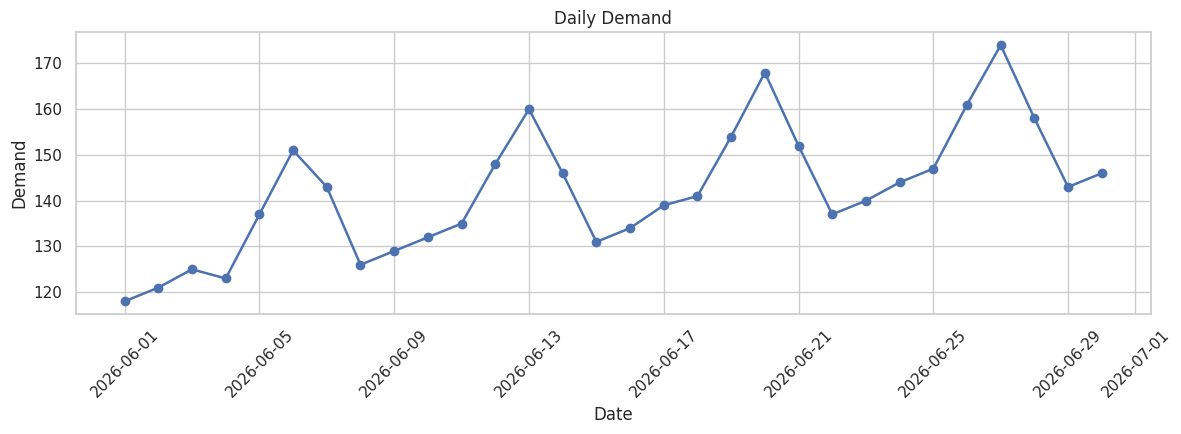

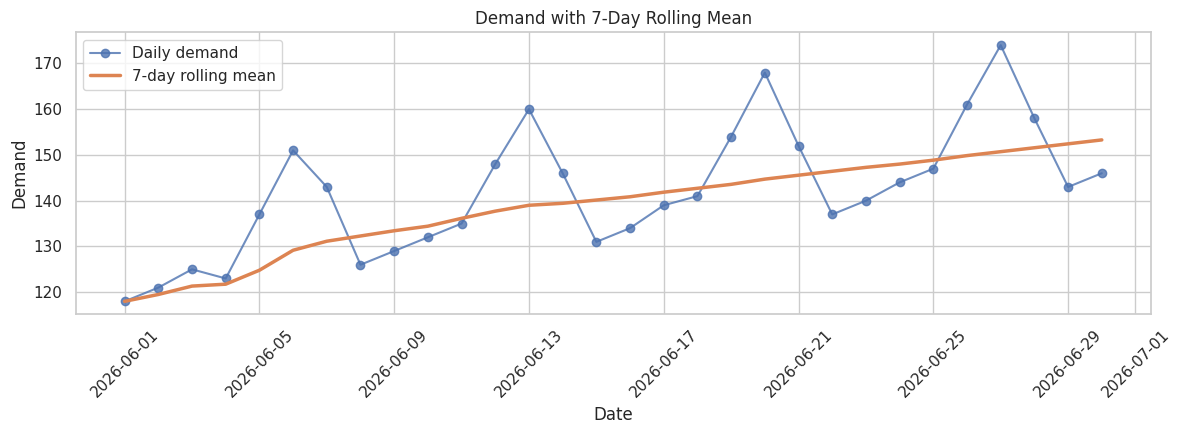

Marketing-event days: 8
Holiday days: 4


In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df.index, df["demand"], marker="o", linewidth=1.8)
ax.set(title="Daily Demand", xlabel="Date", ylabel="Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(df.index, df["demand"], marker="o", label="Daily demand", alpha=.8)
ax.plot(df.index, df["demand"].rolling(7, min_periods=1).mean(),
        linewidth=2.5, label="7-day rolling mean")
ax.set(title="Demand with 7-Day Rolling Mean", xlabel="Date", ylabel="Demand")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Marketing-event days:", int(df["marketing_event"].sum()))
print("Holiday days:", int(df["holiday"].sum()))

## 2. Trend, seasonality, and residual decomposition

A weekly period (`period=7`) is used as a reasonable daily-data hypothesis. Seasonal decomposition needs at least two complete cycles; with only 30 observations, the estimated weekly pattern is fragile and should be treated as exploratory.

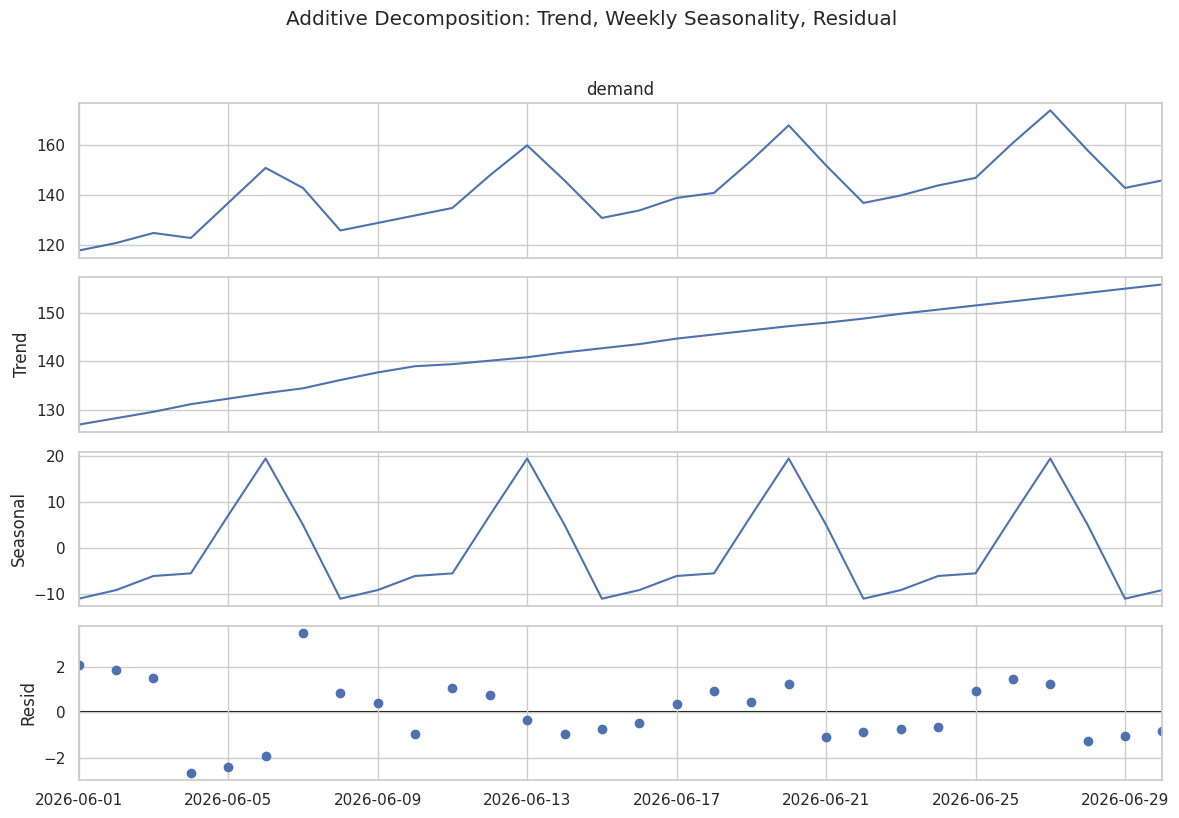

Mean estimated seasonal component by day of week:


,seasonal_component
day_of_week,
Friday,7.12
Monday,-11.00
Saturday,19.48
Sunday,5.07
Thursday,-5.49
Tuesday,-9.12
Wednesday,-6.06


In [ ]:
decomp = seasonal_decompose(df["demand"], model="additive", period=7, extrapolate_trend="freq")
fig = decomp.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Additive Decomposition: Trend, Weekly Seasonality, Residual", y=1.02)
plt.tight_layout()
plt.show()

print("Mean estimated seasonal component by day of week:")
seasonal_by_dow = pd.DataFrame({
    "seasonal_component": decomp.seasonal,
    "day_of_week": decomp.seasonal.index.day_name()
}).groupby("day_of_week")["seasonal_component"].mean()
display(seasonal_by_dow.to_frame().round(2))

## 3. Stationarity: Augmented Dickey-Fuller (ADF) test

In [ ]:
def adf_report(series, label):
    result = adfuller(series.dropna(), autolag="AIC")
    report = {
        "series": label,
        "ADF statistic": result[0],
        "p-value": result[1],
        "lags used": result[2],
        "observations used": result[3],
        "5% critical value": result[4].get("5%", np.nan)
    }
    return report

adf_original = adf_report(df["demand"], "Original demand")
demand_diff = df["demand"].diff().dropna()
adf_diff = adf_report(demand_diff, "First difference")
display(pd.DataFrame([adf_original, adf_diff]).set_index("series").round(4))

print("Interpretation: at a 5% significance level, p < 0.05 is evidence against a unit root.")
print("Because the sample is very small, ADF power is limited; do not use this test alone to decide the model.")

,ADF statistic,p-value,lags used,observations used,5% critical value
series,,,,,
Original demand,-0.9039,0.7867,7,22,-3.0054
First difference,-2.2336,0.1943,6,22,-3.0054


Interpretation: at a 5% significance level, p < 0.05 is evidence against a unit root.
Because the sample is very small, ADF power is limited; do not use this test alone to decide the model.


## 4. Chronological train/test split and baseline

The last 7 days are held out as a test set. This preserves time order and avoids random shuffling. The training set is very small (23 days), so ARIMA parameter estimates and model rankings may be unstable. A simple last-value forecast is included as a baseline.

Training observations: 23 (2026-06-01 to 2026-06-23)
Test observations: 7 (2026-06-24 to 2026-06-30)


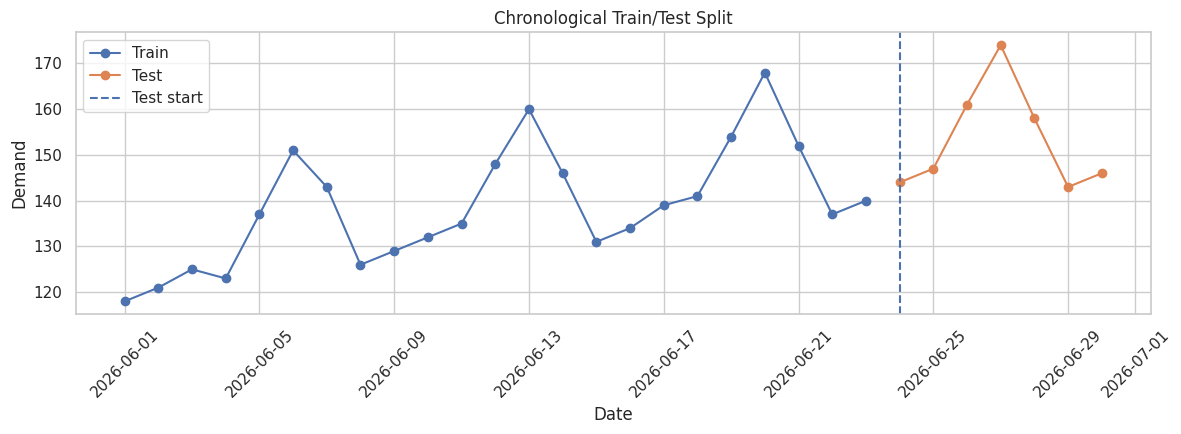

In [ ]:
TEST_DAYS = 7
train = df["demand"].iloc[:-TEST_DAYS]
test = df["demand"].iloc[-TEST_DAYS:]

print(f"Training observations: {len(train)} ({train.index.min().date()} to {train.index.max().date()})")
print(f"Test observations: {len(test)} ({test.index.min().date()} to {test.index.max().date()})")

plt.figure(figsize=(12, 4.5))
plt.plot(train.index, train, marker="o", label="Train")
plt.plot(test.index, test, marker="o", label="Test")
plt.axvline(test.index[0], linestyle="--", label="Test start")
plt.title("Chronological Train/Test Split")
plt.xlabel("Date"); plt.ylabel("Demand"); plt.legend()
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

baseline_forecast = np.repeat(train.iloc[-1], len(test))

## 5. ARIMA model selection

A compact grid of non-seasonal ARIMA orders is compared using AIC on the training set. The order with the lowest AIC is then evaluated on the held-out period. With this short series, treat the selected order as a candidate, not proof of a universally best model. Seasonal ARIMA is not aggressively tuned because the training window contains only a few weekly cycles.

In [ ]:
orders = [(p, d, q) for p in range(3) for d in range(2) for q in range(3)]
aic_rows = []
fitted_models = {}

for order in orders:
    try:
        model = ARIMA(train, order=order, enforce_stationarity=False, enforce_invertibility=False)
        fit = model.fit()
        aic_rows.append({"order": str(order), "p": order[0], "d": order[1], "q": order[2], "AIC": fit.aic})
        fitted_models[order] = fit
    except Exception as exc:
        aic_rows.append({"order": str(order), "p": order[0], "d": order[1], "q": order[2],
                         "AIC": np.nan, "error": str(exc)[:120]})

aic_table = pd.DataFrame(aic_rows).dropna(subset=["AIC"]).sort_values("AIC").reset_index(drop=True)
display(aic_table.head(10).round(3))
best_order_text = aic_table.iloc[0]["order"]
best_order = eval(best_order_text)
best_fit = fitted_models[best_order]
print("Selected ARIMA order by training AIC:", best_order)

,order,p,d,q,AIC
0,"(0, 1, 2)",0,1,2,139.835
1,"(1, 1, 2)",1,1,2,140.064
2,"(2, 1, 2)",2,1,2,140.612
3,"(0, 0, 2)",0,0,2,140.928
4,"(1, 0, 2)",1,0,2,142.917
5,"(2, 0, 2)",2,0,2,143.539
6,"(2, 1, 1)",2,1,1,147.936
7,"(2, 1, 0)",2,1,0,148.413
8,"(0, 1, 1)",0,1,1,149.348
9,"(1, 0, 1)",1,0,1,150.496


Selected ARIMA order by training AIC: (0, 1, 2)


## 6. Evaluate forecast accuracy on the holdout

,model,MAPE (%),RMSE
0,Last-value baseline,8.246,17.034
1,"ARIMA(0, 1, 2)",5.880,14.163


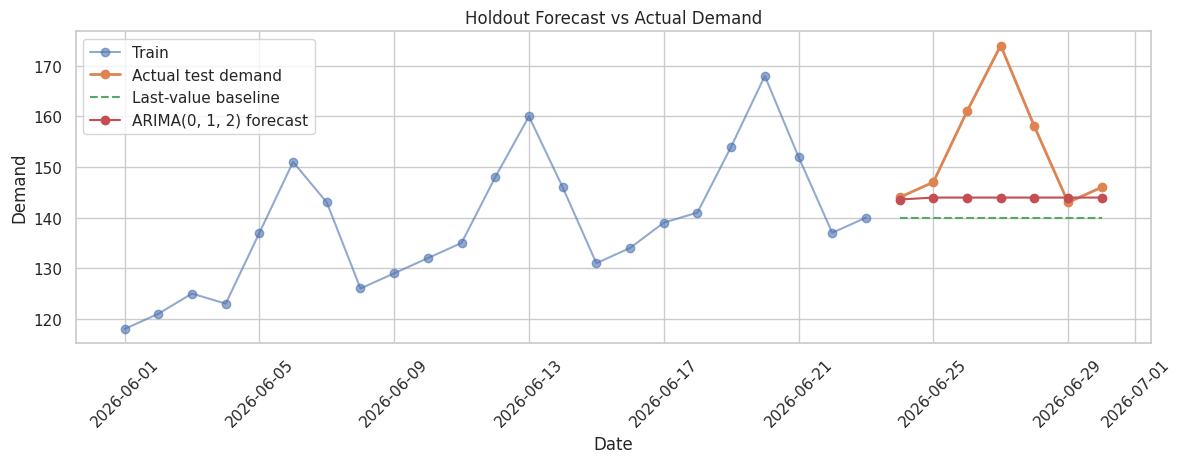

Mean holdout residual (actual - forecast): 9.379


In [ ]:
arima_test_forecast = best_fit.get_forecast(steps=len(test)).predicted_mean
arima_test_forecast.index = test.index

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mape_percent(y_true, y_pred):
    return float(mean_absolute_percentage_error(y_true, y_pred) * 100)

metrics = pd.DataFrame([
    {"model": "Last-value baseline", "MAPE (%)": mape_percent(test, baseline_forecast),
     "RMSE": rmse(test, baseline_forecast)},
    {"model": f"ARIMA{best_order}", "MAPE (%)": mape_percent(test, arima_test_forecast),
     "RMSE": rmse(test, arima_test_forecast)}
])
display(metrics.round(3))

plt.figure(figsize=(12, 4.8))
plt.plot(train.index, train, label="Train", marker="o", alpha=.6)
plt.plot(test.index, test, label="Actual test demand", marker="o", linewidth=2)
plt.plot(test.index, baseline_forecast, label="Last-value baseline", linestyle="--")
plt.plot(test.index, arima_test_forecast, label=f"ARIMA{best_order} forecast", marker="o")
plt.title("Holdout Forecast vs Actual Demand")
plt.xlabel("Date"); plt.ylabel("Demand"); plt.legend()
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

residuals = test - arima_test_forecast
print("Mean holdout residual (actual - forecast):", round(float(residuals.mean()), 3))

## 7. Refit on all observations and forecast the next 30 days

After the holdout evaluation, the selected ARIMA order is refit on all 30 observations to create the final 30-day projection. Forecast intervals communicate uncertainty; with such limited history, these intervals and point forecasts should be interpreted cautiously. The forecast does not assume future marketing events or holidays because those future values are not provided.

,date,forecast_demand,lower_95_ci,upper_95_ci
0,2026-07-01,148.70,133.39,164.02
1,2026-07-02,150.21,126.98,173.44
2,2026-07-03,150.21,126.40,174.03
3,2026-07-04,150.21,125.82,174.61
4,2026-07-05,150.21,125.26,175.17
5,2026-07-06,150.21,124.72,175.71
6,2026-07-07,150.21,124.18,176.25
7,2026-07-08,150.21,123.65,176.78
8,2026-07-09,150.21,123.14,177.29
9,2026-07-10,150.21,122.63,177.80


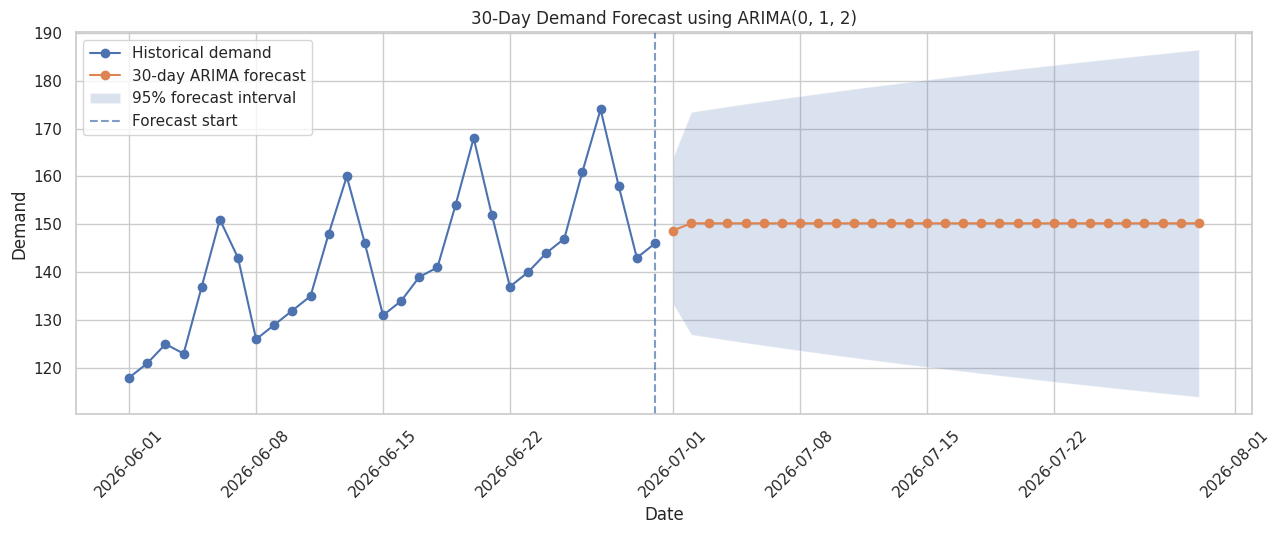

Saved forecast table to demand_30_day_forecast.csv


In [ ]:
final_model = ARIMA(df["demand"], order=best_order,
                    enforce_stationarity=False, enforce_invertibility=False).fit()
forecast_steps = 30
forecast_obj = final_model.get_forecast(steps=forecast_steps)
forecast_mean = forecast_obj.predicted_mean
forecast_ci = forecast_obj.conf_int()

future_dates = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=forecast_steps, freq="D")
forecast_mean.index = future_dates
forecast_ci.index = future_dates

forecast_table = pd.DataFrame({
    "date": future_dates,
    "forecast_demand": forecast_mean.values,
    "lower_95_ci": forecast_ci.iloc[:, 0].values,
    "upper_95_ci": forecast_ci.iloc[:, 1].values
})
display(forecast_table.round(2))

plt.figure(figsize=(13, 5.5))
plt.plot(df.index, df["demand"], marker="o", label="Historical demand")
plt.plot(future_dates, forecast_mean, marker="o", label="30-day ARIMA forecast")
plt.fill_between(future_dates, forecast_ci.iloc[:, 0].values, forecast_ci.iloc[:, 1].values,
                 alpha=.2, label="95% forecast interval")
plt.axvline(df.index[-1], linestyle="--", alpha=.7, label="Forecast start")
plt.title(f"30-Day Demand Forecast using ARIMA{best_order}")
plt.xlabel("Date"); plt.ylabel("Demand"); plt.legend()
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

forecast_table.to_csv("demand_30_day_forecast.csv", index=False)
print("Saved forecast table to demand_30_day_forecast.csv")

## 8. Conclusions and limitations

Review the ADF output, decomposition plots, model-selection table, holdout metrics, and forecast intervals before writing a final conclusion.

- The ADF test checks evidence for a unit root; first differencing is a common option when a series is non-stationary.
- The ARIMA order is selected by AIC on the training window, while MAPE and RMSE are measured on a later holdout window.
- Compare ARIMA with the last-value baseline; a more complex model is not automatically better.
- Only 30 days are supplied. This is not enough history to estimate yearly or stable long-run seasonality, and the seven-day holdout leaves just 23 training points.
- MAPE is reported as a percentage and RMSE in demand units. Both summarize error but do not establish that the model will generalize.
- The file contains `marketing_event` and `holiday` flags, but the primary model is univariate because future flag values are unavailable. A future extension could use SARIMAX with known future regressors, or Prophet with more historical data and planned regressors.
- The 30-day forecast is a projection under the fitted model, not a guarantee.

## Reproducibility

Install the required packages:

```bash
pip install pandas numpy matplotlib seaborn statsmodels scikit-learn jupyter
```

Place `daily-demand-series.csv` next to the notebook, open the notebook in Jupyter or VS Code, and run all cells from top to bottom.